# 03 · Why Models Cannot Spell

> **The explanatory core.** Ask a model how many r's are in *strawberry* and it
> may say two. Not stupidity — tokenization. The word arrives as one or two
> opaque tokens, so the separate r's were never in the input.

In [1]:
import os
import sys
import pathlib

_p = pathlib.Path.cwd()
while not (_p / "pyproject.toml").exists() and _p != _p.parent:
    _p = _p.parent
os.chdir(_p)
if str(_p) not in sys.path:
    sys.path.insert(0, str(_p))

import json

import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 11

from src.artifacts import save_figure, save_json

print("repo root:", _p)

repo root: /workspaces/tokenization_101


## Tokenize `strawberry`

In [2]:
from src.bpe import BPETokenizer
from src.datasets.corpora import spelling_words, training_corpus
from src.probes.spelling import count_letter, probe_spelling

tok = BPETokenizer().train(training_corpus(60_000), vocab_size=512)

p = probe_spelling(tok, "strawberry")
print("pieces:", p.pieces)
print(f"{p.num_characters} characters -> {p.num_tokens} tokens")
print("each character its own token (visible)?", p.characters_visible)
print("true count of 'r':", count_letter("strawberry", "r"))

pieces: ['st', 'r', 'a', 'w', 'b', 'er', 'r', 'y']
10 characters -> 8 tokens
each character its own token (visible)? False
true count of 'r': 3


The model is asked to count something it never received as separate symbols. Let's confirm the pattern across a list of words.

In [3]:
rows = []
for word in spelling_words():
    pr = probe_spelling(tok, word)
    rows.append(
        {
            "word": word,
            "num_characters": pr.num_characters,
            "num_tokens": pr.num_tokens,
            "pieces": pr.pieces,
            "characters_visible": pr.characters_visible,
        }
    )
    print(f"{word:>32}  {pr.num_characters:>3} chars -> {pr.num_tokens:>2} tokens")

print("saved:", save_json("03_spelling", rows))

                      strawberry   10 chars ->  8 tokens
                     mississippi   11 chars ->  8 tokens
                      bookkeeper   10 chars ->  8 tokens
                    unbelievable   12 chars ->  8 tokens
                    tokenization   12 chars ->  5 tokens
    antidisestablishmentarianism   28 chars -> 19 tokens
saved: /workspaces/tokenization_101/outputs/data/03_spelling.json


saved: /workspaces/tokenization_101/outputs/figures/03_chars_vs_tokens.png


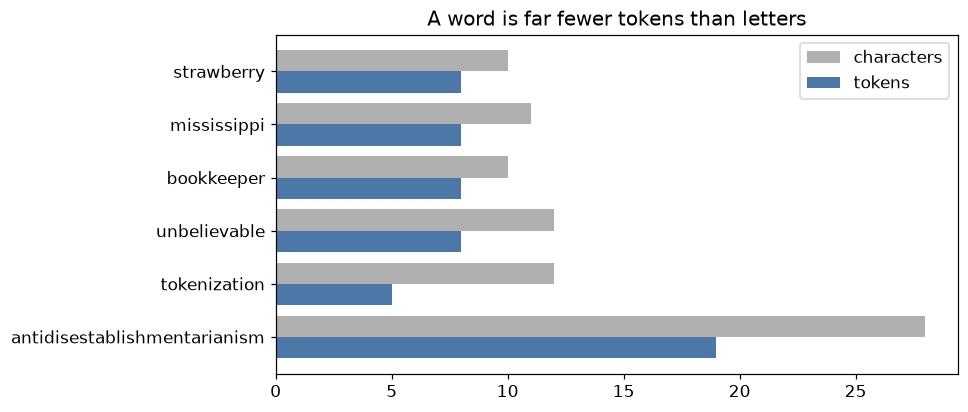

In [4]:
import numpy as np

words = [r["word"] for r in rows]
num_chars = [r["num_characters"] for r in rows]
num_tokens = [r["num_tokens"] for r in rows]
y = np.arange(len(words))

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(y - 0.2, num_chars, height=0.4, label="characters", color="#B0B0B0")
ax.barh(y + 0.2, num_tokens, height=0.4, label="tokens", color="#4C78A8")
ax.set_yticks(y)
ax.set_yticklabels(words)
ax.invert_yaxis()
ax.legend()
ax.set_title("A word is far fewer tokens than letters")
print("saved:", save_figure(fig, "03_chars_vs_tokens"))
plt.show()

## Brittle boundaries: a space or a capital changes everything

In [5]:
variants = ["strawberry", " strawberry", "Strawberry", "STRAWBERRY"]
vrows = []
for v in variants:
    pr = probe_spelling(tok, v)
    vrows.append({"variant": v, "num_tokens": pr.num_tokens, "pieces": pr.pieces})
    print(f"{v!r:>14}  {pr.num_tokens} tokens  {pr.pieces}")

print("saved:", save_json("03_variants", vrows))

  'strawberry'  8 tokens  ['st', 'r', 'a', 'w', 'b', 'er', 'r', 'y']
 ' strawberry'  8 tokens  [' st', 'r', 'a', 'w', 'b', 'er', 'r', 'y']
  'Strawberry'  9 tokens  ['S', 't', 'r', 'a', 'w', 'b', 'er', 'r', 'y']
  'STRAWBERRY'  10 tokens  ['S', 'T', 'R', 'A', 'W', 'B', 'E', 'R', 'R', 'Y']
saved: /workspaces/tokenization_101/outputs/data/03_variants.json


**Takeaway.** Letter-counting, reversing, and spelling ask the model to see
inside opaque chunks. Give it a tool or a character-level view instead — and
stop reading these as reasoning failures.